In [36]:
import pandas as pd

client_train_data = pd.read_csv("data/client_train.csv", low_memory=False)
invoice_train_data = pd.read_csv("data/invoice_train.csv",  low_memory=False)

In [ ]:
train_data = client_train_data.merge(invoice_train_data, on="client_id", how = "left", validate="1:m")

<Axes: xlabel='target', ylabel='count'>

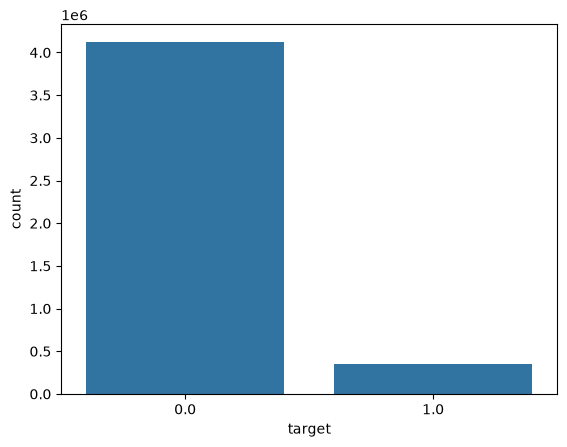

In [52]:
import seaborn as sns
sns.countplot(data=train_data, x="target")
# We see a very imbalanced result

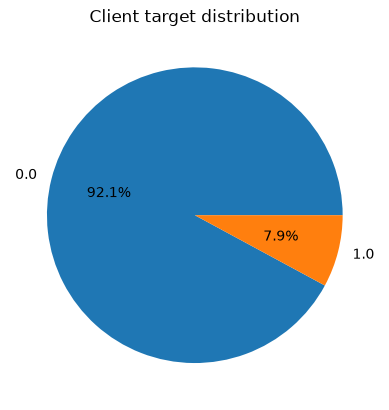

In [53]:
import matplotlib.pyplot as plt

target_counts = train_data["target"].value_counts().sort_index()
plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.1f%%"
)
plt.title("Client target distribution")
plt.show()

In [ ]:
cm = train_data.select_dtypes(include=["number"]).corr(method="pearson")
sns.heatmap(cm)

ValueError: could not convert string to float: 'train_Client_0'

In [38]:
X = train_data[
    ["client_catg", "region", "invoice_date",
     "consommation_level_1", "consommation_level_2",
     "consommation_level_3", "consommation_level_4"]
]
y = train_data["target"]

In [39]:
X["invoice_date"] = pd.to_datetime(X["invoice_date"]).astype("int64")

d={"ELEC":0,"GAZ":1}
#X['counter_type']=X['counter_type'].map(d)

X['client_catg'] = X['client_catg'].astype(int)
#X['disrict'] = X['disrict'].astype(int)

In [40]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y, train_size=0.75)

In [41]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
# Convert the date column to a numeric timestamp before scaling
x_scaled = sc.fit_transform(X_train)

In [42]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

lgbm = LGBMClassifier()
pg = {
    "learning_rate": [0.01, 0.1, 0.2, 1],
    "n_estimators": [10, 100, 200],
    "subsample_for_bin": [1000, 10000, 20000],
}
gscv = GridSearchCV(
    estimator=lgbm,
    param_grid=pg,
    n_jobs=8,
    scoring="roc_auc"
)

gscv.fit(x_scaled, y_train)

[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
[LightGBM] [Info] Number of positive: 264834, number of negative: 3092727
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.037504 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1158
[LightGBM] [Info] Number of data points in the train set: 3357561, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.078877 -> initscore=-2.457705
[LightGBM] [Info] Start training from score -2.457705


,estimator,LGBMClassifier()
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'n_estimators': [10, 100, ...], 'subsample_for_bin': [1000, 10000, ...]}"
,scoring,'roc_auc'
,n_jobs,8
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,boosting_type,'gbdt'


In [44]:
y_pred = gscv.predict(X_test)

<Axes: >

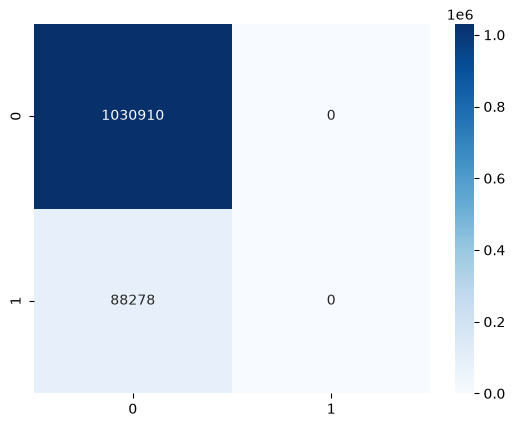

In [47]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
